# M2 retry: methods, real results, and why M3 differs

Selected revised variant: **R4-BoxRefine**. The original M2-C remains the stronger accuracy choice by validation AP50. The revised detector should not replace it on accuracy grounds; its speed and methodological comparisons remain useful results. This notebook reads the completed
separate run `results/m2/revision_20261117/full`. The old report/results are preserved. M3's screenshot
is a reported reference, not a reproduced experiment. The official test set was
previously evaluated; any revised test score is explicitly a follow-up.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display,Image,Markdown
roots=[Path.cwd(),*Path.cwd().parents]
ROOT=next(p for base in roots for p in [base,base/"Comp9517-bird-detection"] if (p/"m2_ml/dense_detector.py").exists())
RUN=ROOT/'results/m2/revision_20261117/full'
protocol=json.loads((RUN/"protocol.json").read_text())
manifest=json.loads((RUN/"manifest.json").read_text())

## 1. The four reference steps, implemented as a detector

1. Search multiple window sizes/aspect ratios.
2. Describe each window with HOG, optionally HSV histograms.
3. Train an SVM on bird/background windows, then mine difficult training false alarms.
4. Apply score-ordered NMS to remove duplicates.

The crucial correction is **what counts as a training window**. Tight GT crops
alone are unlike the shifted, contextual windows encountered by an image detector.
Here positives and negatives come from the same dense maps used for detection.

## 2. Dense features and matching geometry

A 48 × 48 feature window includes context around its central 36 × 36 predicted
box. Six-pixel cells, 2 × 2-cell blocks and nine bins give 1,764 HOG values.
Up to four matched positions/scales per bird provide positive variation. Integral
cell histograms add 24 HSV values efficiently. The full level is described once;
overlapping descriptors are sliced from it instead of recomputed per crop.

In [2]:
display(pd.DataFrame([protocol["config"]]).T)
audit=pd.read_csv(RUN/"training_audit.csv")
display(audit[["birds","birds_with_positive_windows","positive_windows","negative_windows"]].sum().to_frame("Count"))
print("Templates:",protocol["templates"])

,0
seed,42.0
cell_size,6.0
window_cells,8.0
context_cells,1.0
orientations,9.0
hsv_bins,8.0
templates,12.0
positives_per_bird,4.0
negatives_per_image,40.0
positive_iou,0.5


,Count
birds,8663
birds_with_positive_windows,8465
positive_windows,33648
negative_windows,54760


Templates: [[10, 10], [17, 15], [21, 30], [31, 21], [42, 32], [36, 52], [69, 46], [66, 82], [124, 71], [108, 124], [196, 145], [303, 282]]


## 3. Controlled variants and additional classical experiments

R1/R2 compare HOG with HOG+HSV using identical windows. R3 adds one training-only
mining pass. R4 adds ridge coordinate refinement; it remains a handcrafted-feature
method. R5 uses train-only PCA and an approximate RBF SVM to rerank initial
proposals. Those last two stages are explicit additional ablations, not hidden
changes presented as the basic screenshot method. No neural features or
pretrained object-detector weights are used by M2.

,variant,C,nms_iou,AP50,AP50_95,AP50_small,AP50_medium,AP50_large,images,mean_inference_seconds
0,R1-HOG,0.1,0.5,0.0314,0.0080,0.0107,0.0897,0.0896,291,0.3566
1,R2-HOG-HSV,0.1,0.5,0.0296,0.0076,0.0090,0.0899,0.0956,291,0.9524
2,R3-HardNeg,0.1,0.5,0.0258,0.0059,0.0042,0.0579,0.0541,291,0.3457
3,R4-BoxRefine,0.1,0.5,0.0410,0.0120,0.0069,0.0919,0.0785,291,0.4024
4,R5-KernelSVM,0.1,0.5,0.0280,0.0066,0.0057,0.0705,0.0888,291,1.0719


,variant,C,nms_iou,AP50,AP50_95,AP50_small,AP50_medium,AP50_large
0,R1-HOG,0.01,0.3,0.0269,0.0062,0.0086,0.1106,0.0877
1,R1-HOG,0.01,0.5,0.0291,0.0075,0.0096,0.0992,0.0896
2,R1-HOG,0.10,0.3,0.0291,0.0069,0.0089,0.1034,0.0925
3,R1-HOG,0.10,0.5,0.0314,0.0080,0.0107,0.0897,0.0896
4,R1-HOG,1.00,0.3,0.0290,0.0067,0.0096,0.0959,0.0965
5,R1-HOG,1.00,0.5,0.0305,0.0077,0.0109,0.0818,0.0877
6,R2-HOG-HSV,0.01,0.3,0.0241,0.0055,0.0072,0.1039,0.0919
7,R2-HOG-HSV,0.01,0.5,0.0262,0.0067,0.0081,0.0951,0.0942
8,R2-HOG-HSV,0.10,0.3,0.0277,0.0065,0.0079,0.1028,0.0950
9,R2-HOG-HSV,0.10,0.5,0.0296,0.0076,0.0090,0.0899,0.0956


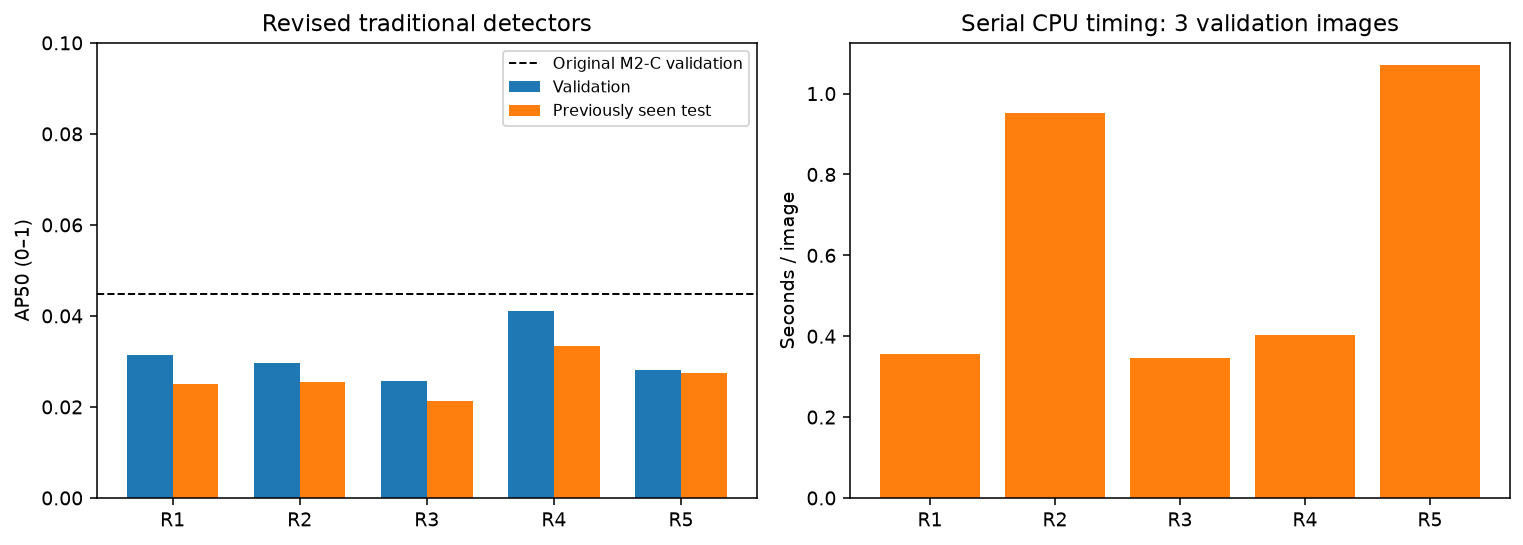

In [3]:
val=pd.read_csv(RUN/"validation_summary.csv")
display(val.round(4))
display(pd.read_csv(RUN/"validation_search.csv").round(4))
display(Image(filename=str(RUN/"revision_comparison.png")))

## 4. Follow-up test and timing boundaries

Selection uses validation only; `FROZEN_REVISION.json` predates follow-up test
inference. Because this test set and failure images were already inspected in the
original work, this is not a new untouched holdout. Serial latency uses three
validation images, with one numerical thread. It includes image loading through
postprocessing. It is different from model-only GPU milliseconds.

In [4]:
if (RUN/"followup_test_summary.csv").exists():display(pd.read_csv(RUN/"followup_test_summary.csv").round(4))
display(pd.read_csv(RUN/"serial_times.csv").round(4))
print("Frozen choices:",json.loads((RUN/"FROZEN_REVISION.json").read_text()))

,variant,images,AP50,AP50_95,AP50_small,AP50_medium,AP50_large,previously_seen_test
0,R1-HOG,240,0.0250,0.0069,0.0225,0.0412,0.1312,True
1,R2-HOG-HSV,240,0.0256,0.0066,0.0206,0.0451,0.1323,True
2,R3-HardNeg,240,0.0214,0.0056,0.0074,0.0243,0.0784,True
3,R4-BoxRefine,240,0.0334,0.0102,0.0110,0.0393,0.1142,True
4,R5-KernelSVM,240,0.0276,0.0052,0.0072,0.0509,0.0849,True


,variant,image_id,seconds
0,R1-HOG,beach_bird_1395,0.3831
1,R1-HOG,beach_bird_1560,0.3445
2,R1-HOG,beach_bird_1594,0.3422
3,R2-HOG-HSV,beach_bird_1395,0.9833
4,R2-HOG-HSV,beach_bird_1560,0.9553
5,R2-HOG-HSV,beach_bird_1594,0.9185
6,R3-HardNeg,beach_bird_1395,0.3528
7,R3-HardNeg,beach_bird_1560,0.3425
8,R3-HardNeg,beach_bird_1594,0.3418
9,R4-BoxRefine,beach_bird_1395,0.4202


Frozen choices: {'selected': 'R4-BoxRefine', 'chosen': {'R1-HOG': {'variant': 'R1-HOG', 'C': 0.1, 'nms_iou': 0.5, 'AP50': 0.03135729990466818, 'AP50_95': 0.008037863144262298, 'AP50_small': 0.010671044003215516, 'AP50_medium': 0.0897000386038687, 'AP50_large': 0.08963002522890673}, 'R2-HOG-HSV': {'variant': 'R2-HOG-HSV', 'C': 0.1, 'nms_iou': 0.5, 'AP50': 0.029628489108359458, 'AP50_95': 0.007562305727606829, 'AP50_small': 0.00898383892633171, 'AP50_medium': 0.089899200158148, 'AP50_large': 0.09556371612786566}, 'R3-HardNeg': {'variant': 'R3-HardNeg', 'C': 0.1, 'nms_iou': 0.5, 'AP50': 0.025801200951758377, 'AP50_95': 0.005882239377366011, 'AP50_small': 0.004225424602613194, 'AP50_medium': 0.05785436457382416, 'AP50_large': 0.054072659978039686}, 'R4-BoxRefine': {'variant': 'R4-BoxRefine', 'C': 0.1, 'nms_iou': 0.5, 'AP50': 0.04101337145061084, 'AP50_95': 0.012036678607808328, 'AP50_small': 0.006913340829813796, 'AP50_medium': 0.09190750653823396, 'AP50_large': 0.0785213851052781}, 'R5-Ke

## 5. Why M3 can be much stronger

M3 learns image features and coordinates. Standard YOLO11 checkpoints transfer
COCO knowledge, including a bird class; the screenshot's actual initialisation
needs confirmation. RT-DETR learns multiscale/contextual representations and
uses transformer predictions. Fixed HOG cannot acquire those learned semantics
simply by adding NMS. Dense sharing reduces computation but does not change this
representation difference.

The local folder only supplied M3 inference, not its training or weights. Its
loader is now architecture-aware and records settings/timing metadata. Read the
audit below for confirmed facts, unknowns and sources.

In [5]:
display(Markdown((ROOT/"m2_ml/M3_comparison_audit.md").read_text()))

# Why M3 can score much higher, and what the current folder proves

Reviewed 17 November 2026. The two supplied screenshots are reference material;
their method description informed the M2 retry. Their scores are not measurements
reproduced by this audit.

## 1. What is actually available

The local `m3_dl/` originally contained only `predict.py` and an empty
`__init__.py`. A search including ignored project files found no M3 `.pt`
checkpoints, training notebooks, `args.yaml`, learning curves or prediction files.
`requirements-dl.txt` declares PyTorch/Ultralytics. The README says deep training
is performed on Colab. Thus the inference implementation can be audited, but
the exact training procedure and screenshot scores cannot be reconstructed from
this folder alone.

The supplied table reports:

| Reference model | Reported AP50 | Reported AP50–95 | Reported small-object AP | Training | Inference |
|---|---:|---:|---:|---:|---:|
| RT-DETR-L | 0.891 | 0.501 | 0.823 | 17.7 min | 11 ms |
| YOLO11 default | 0.857 | 0.472 | 0.738 | 8.1 min | 5 ms |
| YOLO11 without mosaic | 0.842 | 0.461 | 0.697 | 3.2 min | 4 ms |

These are **user-reported, unverified** values. The evaluated split, YOLO model
size, checkpoint initialisation, actual epochs, seed, hardware and timing scope
are absent. The small-object column must also specify its IoU range: AP50-small
and AP50–95-small are different metrics.

## 2. Why the approach has an advantage

**Representation.** M2 fixes the visual representation to HOG edges and optional
colour statistics. YOLO11 learns its visual representation and detection heads.
This gives it a way to distinguish object appearance from background texture
beyond a linear combination of fixed edge histograms. Official YOLO11 `.pt`
models are COCO-pretrained; COCO includes `bird` (class index 14). If those weights
initialised M3, prior bird/object knowledge is transferred before fine-tuning on
the 1,369 beach training images. That initialisation is typical, not confirmed
for this screenshot. [YOLO11 documentation](https://docs.ultralytics.com/models/yolo11/),
[COCO class list](https://docs.ultralytics.com/datasets/detect/coco/).

**Scale and context.** RT-DETR's backbone/hybrid encoder combines multiscale
features and its transformer decoder predicts objects. These learned contextual
features can help with small or overlapping birds. Dense HOG also shares work
over a pyramid, but its representation remains handcrafted. The RT-DETR
architecture is described in the [original paper](https://arxiv.org/abs/2304.08069)
and [official model documentation](https://docs.ultralytics.com/models/rtdetr/).

**Localisation.** M3 learns bounding-box coordinates. The original M2 classifier
only scored preset boxes and did not refine their coordinates. NMS removes
duplicates; it cannot learn where the bird begins or ends. The revision therefore
includes a separate, explicitly labelled linear box-regression ablation using
HOG features, following the standard centre-offset/log-size idea; it is not a
neural detector. See [R-CNN Appendix C](https://arxiv.org/html/1311.2524v5).

**Training examples.** An image detector is exposed to positions, scales and hard
backgrounds at search time. Training M2 only on exact GT crops and a few random
backgrounds underrepresents those conditions. In the original M2 run, validation
crop ROC AUC was about 0.94, but full-image AP50 was only 0.017 before mining.
Those different tasks must not be confused. The revision uses aligned search
windows, position/scale variation, context and a much larger training-only mining
pass. These changes address a real implementation weakness; they do not make
HOG equivalent to learned neural features.

The low-false-positive tail matters especially for sliding windows. As an
illustration, a background false-positive rate of only 0.1% over the original
47,527 windows would give roughly 48 raw false alarms before NMS, while this
dataset averages about 6.3 birds/image. This is illustrative arithmetic, not a
measured M2 false-positive rate. A good crop ROC AUC does not guarantee that tail
is good enough for detection. Raising a display threshold may hide boxes but does
not improve the ordering of correct and incorrect detections that AP measures.

**Mosaic.** The supplied default/no-mosaic comparison differs by 0.015 AP50 and
0.041 in the reported small-object column. Mosaic changes scale/context during
training, but the table alone does not establish a controlled causal effect:
seeds, initial weights, epochs and other settings need to match. Different
training durations can reflect augmentation cost or different stopping points.
[Ultralytics training settings](https://docs.ultralytics.com/modes/train/).

## 3. Why the speed figures are not directly comparable

The previous M2 numbers were CPU end-to-end timings, including image loading,
feature extraction and NMS. The screenshot's 4–11 ms could be model-only GPU
timings; this is not established by the screenshot. A neural full-image forward
pass also shares computation rather than independently describing every crop.
The revised M2 likewise computes dense feature maps once per image-pyramid level.
Report hardware, input size, batch size, warm-up, synchronisation and timing scope
before comparing milliseconds to CPU seconds.

## 4. Inference-script issues corrected

The old wrapper loaded every checkpoint with `YOLO(...)`. RT-DETR has its own
predictor/validator and an NMS-free architecture. The revised wrapper provides
`--family`, uses `RTDETR(...)` for RT-DETR, and detects its underlying model when
the checkpoint is generically named `best.pt`. This routing is checked with
mocked loaders; a real neural checkpoint is still needed for an execution test.
[RT-DETR task map](https://docs.ultralytics.com/reference/models/rtdetr/model/),
[YOLO task map](https://docs.ultralytics.com/reference/models/yolo/model/).

The wrapper also rejects an unfiltered multi-class checkpoint: exporting every
COCO class as `bird` would be incorrect. An explicit `--bird-class` can be used
for a multi-class model. Fine-tuned single-class checkpoints continue to work.
Warm-up uses the same prediction options as timed inference. Metadata records
split/image IDs, input size, confidence floor, 300-detection cap, model family,
software/platform, weights hash, and separate end-to-end/model-only timings.
These fixes do not prove that the supplied table was generated by the old wrapper.

Example reproduction when trained weights are supplied:

```bash
python -m m3_dl.predict --family rtdetr --weights PATH/weights/best.pt \
  --split val --name rtdetr_l --imgsz 512 --conf 0.001 --max-det 300
python -m evaluation.evaluate --pred preds/rtdetr_l_val.json --split val
```

## 5. Evaluation boundary for the retry

The original official test set has already been evaluated and its failure images
were inspected in the earlier M2 work. The retry chooses every model and NMS
setting using training/validation only. Any later official-test result is labelled
as a follow-up on a previously seen test set, not as a fresh untouched holdout.
Original results and reports are preserved. The M3 screenshot is kept separately
from locally measured results and is not used as a target to fabricate scores.


## 6. Actual successes and failures

Green dashed boxes are annotations; orange boxes are predictions at a display
threshold selected using validation F1. This threshold does not replace AP's
ranked score range. Examples follow stated criteria and are not proof of a
general causal mechanism.

,role,image_id,ground_truth,predicted,TP,FP,FN,absolute_count_error,errors
0,Successful detection,beach_bird_1582,4,4,4,0,0,0,0.0
1,Misses (≤20 birds),beach_bird_1660,20,17,0,17,20,3,NaN
2,Negative scene,beach_bird_1378,0,27,0,27,0,27,NaN
3,Dense flock,beach_bird_1658,100,34,1,33,99,66,NaN


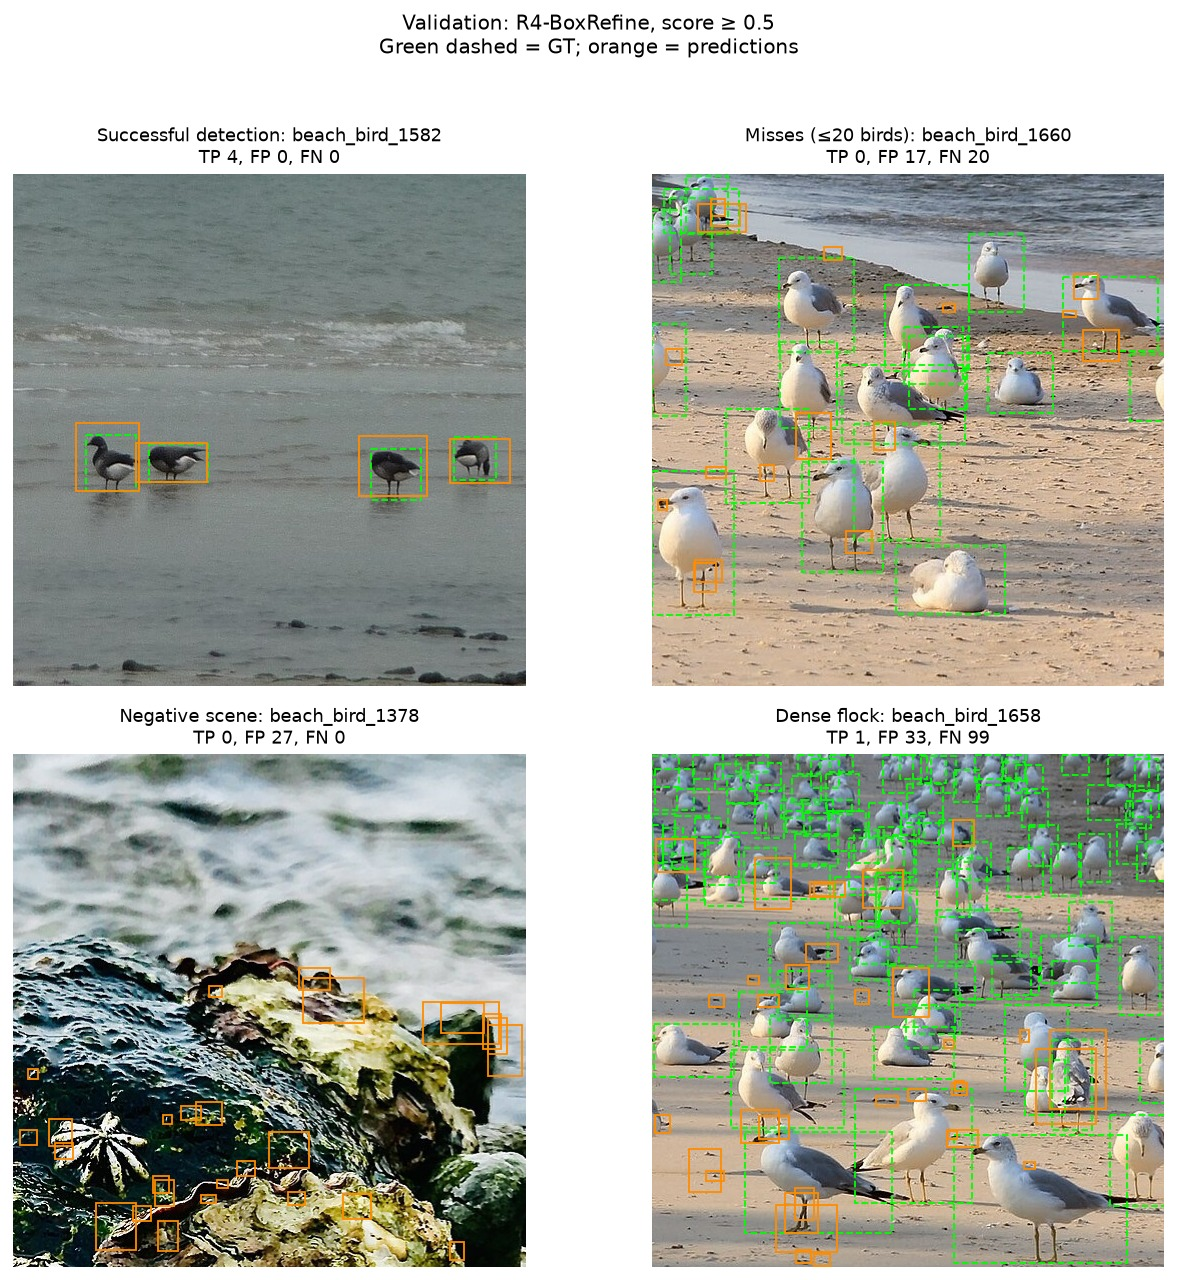

The validation examples show an important distinction between detecting bird-like
parts and localising whole birds. In `beach_bird_1582`, four dark birds against
relatively simple water are all correctly localised. In `beach_bird_1660`, many
small detections lie on parts of much larger birds or on the surrounding ground;
none matches the twenty full-bird annotations at IoU 0.5. The negative image
`beach_bird_1378` produces 27 false detections on high-contrast rock/water texture.
In `beach_bird_1658`, only one of 100 annotations is matched at the display
threshold, alongside 33 false detections. These are observed cases, not a separate
estimate of population performance.

A small candidate's feature support extends only one third beyond its predicted
width/height. A region covering a head may therefore lack the full-body context
needed to decide whether it represents a complete bird. Ridge refinement is
trained on already-overlapping positive proposals, so it is not designed to turn
every tiny part proposal into a correct full-bird box. This is consistent with
the observed localisation and background-confusion failures, without proving that
one feature or stage explains every error. Full-image neural detectors can use
learned contextual features beyond the final output box.


In [6]:
display(pd.read_csv(RUN/"example_selection.csv"))
display(Image(filename=str(RUN/"revision_examples.jpg")))
if (RUN/"visual_review.md").exists():display(Markdown((RUN/"visual_review.md").read_text()))

## 7. Reproduce and read the report

```bash
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 .venv/bin/python -m m2_ml.run_dense \
  --out results/m2/revision_20261117/NEW_RUN --workers 6 --kernel
```

`--evaluate-previous-test` explicitly enables a labelled follow-up test after
validation selection. Use a new run name for a new experiment. Original outputs
are in `results/m2/full/20261114_full/`; revision outputs are separate. The report
is `m2_ml/M2_revision_report.md`; its conclusions use these saved measurements.
The group's final document still needs IEEE formatting and the other methods.